# 🎯 07 — Recommendation Engine
### Scouti Kora — AI Football Scouting System

**Combines all 3 models into one scouting pipeline:**

```
Input: position + budget + age_range + style + reference_player (optional)
  ↓
Step 1 — Hard filters  (position, age, budget)
  ↓
Step 2 — Style filter  (K-Means cluster label)
  ↓
Step 3 — Rank by talent_score (XGBoost 0–100)
  ↓
Step 4 — Re-rank by similarity to reference player (KNN, optional)
  ↓
Output — Top 5 player cards + exportable CSV
```

**Artifacts consumed:**
- `data/processed/master_scouting_dataset.csv`
- `data/processed/style_clusters.csv`
- `data/processed/talent_scores.csv`
- `data/processed/player_index.csv`
- `models/knn_similarity_model.pkl`
- `models/similarity_scaler.pkl`
- `models/similarity_features.pkl`
- `models/xgb_talent_model.pkl`
- `models/talent_features.pkl`
- `models/cluster_models.pkl`

## 📦 0 — Imports & Paths

In [19]:
import pandas as pd
import numpy as np
import pickle
import json
import warnings
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', '{:.2f}'.format)

ROOT      = Path('..').resolve()
PROCESSED = ROOT / 'data' / 'processed'
MODELS    = PROCESSED   # nb04/05/06 saved .pkl files to data/processed/
REPORTS   = ROOT / 'reports'

PROCESSED.mkdir(parents=True, exist_ok=True)
REPORTS.mkdir(parents=True, exist_ok=True)

COLORS = ['#7F77DD', '#1D9E75', '#D85A30', '#378ADD', '#BA7517', '#D4537E']

# ── Style label → position group mapping ─────────────────────────────
STYLE_TO_POSITION = {
    'Target Man':         'Forward',
    'Complete Forward':   'Forward',
    'Pure Poacher':       'Forward',
    'Wide Forward':       'Forward',
    'Deep Playmaker':     'Midfielder',
    'Defensive Midfielder': 'Midfielder',
    'Box-to-Box':         'Midfielder',
    'Creative #10':       'Midfielder',
    'Aggressive Stopper': 'Defender',
    'Defensive CB':       'Defender',
    'Shot-stopper':       'Goalkeeper',
    'Backup GK':          'Goalkeeper',
}

ALL_STYLE_LABELS = sorted(STYLE_TO_POSITION.keys())

print('✅ Ready')
print(f'Available style labels: {ALL_STYLE_LABELS}')

✅ Ready
Available style labels: ['Aggressive Stopper', 'Backup GK', 'Box-to-Box', 'Complete Forward', 'Creative #10', 'Deep Playmaker', 'Defensive CB', 'Defensive Midfielder', 'Pure Poacher', 'Shot-stopper', 'Target Man', 'Wide Forward']


## 📂 1 — Load All Artifacts

In [20]:
def safe_read(path, label):
    p = Path(path)
    if p.exists():
        df = pd.read_csv(p, low_memory=False)
        print(f'  ✅ {label:<35} {len(df):>7,} rows')
        return df
    print(f'  ⚠️  {label:<35} NOT FOUND: {p}')
    return pd.DataFrame()

def safe_pkl(path, label):
    p = Path(path)
    if p.exists():
        with open(p, 'rb') as f:
            obj = pickle.load(f)
        print(f'  ✅ {label:<35} loaded')
        return obj
    print(f'  ⚠️  {label:<35} NOT FOUND: {p}')
    return None

print('Loading CSV artifacts...')
master   = safe_read(PROCESSED / 'master_scouting_dataset.csv', 'master_scouting_dataset')
clusters = safe_read(PROCESSED / 'style_clusters.csv',          'style_clusters')
talent   = safe_read(PROCESSED / 'talent_scores.csv',           'talent_scores')
p_index  = safe_read(PROCESSED / 'player_index.csv',            'player_index')

print('\nLoading model artifacts...')
knn_model    = safe_pkl(MODELS / 'knn_similarity_model.pkl', 'knn_similarity_model')
knn_scaler   = safe_pkl(MODELS / 'similarity_scaler.pkl',   'similarity_scaler')
knn_features = safe_pkl(MODELS / 'similarity_features.pkl', 'similarity_features')
xgb_model    = safe_pkl(MODELS / 'xgb_talent_model.pkl',    'xgb_talent_model')
xgb_features = safe_pkl(MODELS / 'talent_features.pkl',     'talent_features')
cluster_models = safe_pkl(MODELS / 'cluster_models.pkl',    'cluster_models')

Loading CSV artifacts...
  ✅ master_scouting_dataset              11,888 rows
  ✅ style_clusters                        4,363 rows
  ✅ talent_scores                         4,677 rows
  ✅ player_index                          4,817 rows

Loading model artifacts...
  ✅ knn_similarity_model                loaded
  ✅ similarity_scaler                   loaded
  ✅ similarity_features                 loaded
  ✅ xgb_talent_model                    loaded
  ✅ talent_features                     loaded
  ✅ cluster_models                      loaded


## 🧩 2 — Build the Unified Player Table

In [21]:
# ── Use 2024-2025 season as the primary snapshot ──────────────────────
# For players missing 2024-25, fall back to their most recent season.
latest_season = '2024-2025'

current = master[master['season'] == latest_season].copy()
older   = master[~master['Player'].isin(current['Player'])].copy()
if not older.empty:
    older = (
        older.sort_values('season', ascending=False)
             .drop_duplicates('Player', keep='first')
    )

snap = pd.concat([current, older], ignore_index=True)
snap = snap.drop_duplicates('Player', keep='first')
print(f'Player snapshot: {len(snap):,} unique players')
print(f'  From 2024-25:  {len(current):,}')
print(f'  From earlier:  {len(older):,}')

# ── Merge talent scores ───────────────────────────────────────────────
# talent_scores.csv may use 'Player' or 'name_norm' as the key
talent_key = 'Player' if 'Player' in talent.columns else 'name_norm'
snap_key   = 'Player' if talent_key == 'Player' else 'name_norm'

# Keep only the talent score column to avoid duplicate cols
talent_cols = [talent_key] + [c for c in talent.columns
               if 'talent' in c.lower() or 'score' in c.lower()
               and c != talent_key]
talent_slim = talent[talent_cols].drop_duplicates(talent_key, keep='first')

snap = snap.merge(talent_slim, left_on=snap_key, right_on=talent_key,
                  how='left', suffixes=('', '_talent'))

# Normalise the talent score column name
talent_score_col = next(
    (c for c in snap.columns if 'talent_score' in c.lower()), None
)
if talent_score_col and talent_score_col != 'talent_score':
    snap = snap.rename(columns={talent_score_col: 'talent_score'})
elif 'talent_score' not in snap.columns:
    # Fall back: use overall_score if talent_score not available
    snap['talent_score'] = snap.get('overall_score', pd.Series(50.0, index=snap.index))
    print('⚠️  talent_score not found — using overall_score as fallback')

# ── Merge style clusters ──────────────────────────────────────────────
cluster_key = 'Player' if 'Player' in clusters.columns else 'name_norm'
style_col   = next((c for c in clusters.columns
                    if 'style' in c.lower() or 'cluster' in c.lower()
                    and 'label' in c.lower()), None)
if style_col is None:
    # Try any column that contains style label strings
    for c in clusters.columns:
        if clusters[c].dtype == object and clusters[c].isin(ALL_STYLE_LABELS).mean() > 0.3:
            style_col = c
            break

if style_col:
    clusters_slim = clusters[[cluster_key, style_col]].drop_duplicates(cluster_key)
    clusters_slim = clusters_slim.rename(columns={style_col: 'style_label'})
    snap = snap.merge(clusters_slim, left_on=snap_key, right_on=cluster_key,
                      how='left', suffixes=('', '_cl'))
    print(f'Style labels merged — coverage: {snap["style_label"].notna().mean()*100:.1f}%')
else:
    snap['style_label'] = np.nan
    print('⚠️  Could not detect style label column in style_clusters.csv')

# ── Final numeric cleanup ─────────────────────────────────────────────
for c in ['market_value_eur', 'talent_score', 'Age', 'overall_score']:
    if c in snap.columns:
        snap[c] = pd.to_numeric(snap[c], errors='coerce')

print(f'\n✅ Unified table: {len(snap):,} players × {len(snap.columns)} cols')
print(f'   talent_score non-null: {snap["talent_score"].notna().sum():,}')
print(f'   style_label  non-null: {snap["style_label"].notna().sum():,}')

Player snapshot: 4,817 unique players
  From 2024-25:  2,392
  From earlier:  2,425
⚠️  talent_score not found — using overall_score as fallback
Style labels merged — coverage: 71.6%

✅ Unified table: 4,817 players × 73 cols
   talent_score non-null: 4,817
   style_label  non-null: 3,451


## 🔧 3 — Core Engine Functions
Three building blocks used by the recommendation pipeline.

In [22]:
# ─────────────────────────────────────────────────────────────────────
# 3A — HARD FILTER
# Returns the subset of `snap` matching position / age / budget.
# ─────────────────────────────────────────────────────────────────────
def apply_hard_filters(
    df,
    position=None,        # 'Forward' | 'Midfielder' | 'Defender' | 'Goalkeeper'
    max_age=None,         # int
    min_age=None,         # int
    max_budget_eur=None,  # float
    min_minutes=450,      # minimum 5 full games
    leagues=None,         # list of league strings, None = all
):
    out = df.copy()

    # Position filter via multi-hot columns
    if position:
        pos_col = f'pos_{position[:2].upper()}'
        # Map full name to column
        pos_map = {'Forward': 'pos_FW', 'Midfielder': 'pos_MF',
                   'Defender': 'pos_DF', 'Goalkeeper': 'pos_GK'}
        col = pos_map.get(position, pos_col)
        if col in out.columns:
            out = out[out[col] == 1]
        else:
            out = out[out['primary_pos'] == position]

    age_col = 'Age' if 'Age' in out.columns else 'age'
    if min_age and age_col in out.columns:
        out = out[pd.to_numeric(out[age_col], errors='coerce') >= min_age]
    if max_age and age_col in out.columns:
        out = out[pd.to_numeric(out[age_col], errors='coerce') <= max_age]

    if max_budget_eur and 'market_value_eur' in out.columns:
        mv = pd.to_numeric(out['market_value_eur'], errors='coerce')
        out = out[(mv <= max_budget_eur) | mv.isna()]

    if min_minutes and 'minutes_played' in out.columns:
        out = out[pd.to_numeric(out['minutes_played'], errors='coerce') >= min_minutes]

    if leagues and 'league' in out.columns:
        out = out[out['league'].isin(leagues)]

    return out.copy()


# ─────────────────────────────────────────────────────────────────────
# 3B — STYLE FILTER
# Narrows the pool to players with a given style label.
# ─────────────────────────────────────────────────────────────────────
def apply_style_filter(df, style_label=None):
    if not style_label or 'style_label' not in df.columns:
        return df
    styled = df[df['style_label'] == style_label]
    # If the filter eliminates everyone, fall back to unfiltered
    if len(styled) == 0:
        print(f'  ⚠️  No players found with style "{style_label}" — style filter skipped')
        return df
    return styled


# ─────────────────────────────────────────────────────────────────────
# 3C — SIMILARITY RE-RANK
# Given a reference player and a candidate pool, compute cosine
# similarity for every candidate and return similarity scores.
# Uses the pre-fitted KNN model and scaler from nb04.
# ─────────────────────────────────────────────────────────────────────
def compute_similarity_scores(reference_player, candidates_df):
    """
    Returns candidates_df with an added 'similarity_pct' column.
    Falls back to talent_score ranking if KNN artifacts are missing.
    """
    if knn_model is None or knn_scaler is None or knn_features is None:
        print('  ⚠️  KNN artifacts not loaded — skipping similarity re-rank')
        candidates_df = candidates_df.copy()
        candidates_df['similarity_pct'] = np.nan
        return candidates_df

    # Find reference player row in player_index
    ref_matches = p_index[p_index['Player'].str.lower() == reference_player.lower()]
    if ref_matches.empty:
        # Fuzzy fallback
        ref_matches = p_index[
            p_index['Player'].str.lower().str.contains(
                reference_player.lower().split()[0], na=False
            )
        ]
    if ref_matches.empty:
        print(f'  ⚠️  Reference player "{reference_player}" not in index — skipping similarity')
        candidates_df = candidates_df.copy()
        candidates_df['similarity_pct'] = np.nan
        return candidates_df

    ref_row = ref_matches.iloc[0]
    ref_name = ref_row['Player']

    # Build feature matrix for candidates
    avail_features = [f for f in knn_features if f in candidates_df.columns]
    missing_f = [f for f in knn_features if f not in candidates_df.columns]
    if missing_f:
        print(f'  ⚠️  Missing KNN features: {missing_f} — filling with 0')

    cand_feat = candidates_df.copy()
    for f in missing_f:
        cand_feat[f] = 0.0

    X_cand = cand_feat[knn_features].fillna(0).values
    X_cand_scaled = knn_scaler.transform(X_cand)

    # Reference player vector from player_index
    ref_feat_cols = [f for f in knn_features if f in p_index.columns]
    if len(ref_feat_cols) < len(knn_features):
        # Player index doesn't have all features — use snap instead
        ref_snap = snap[snap['Player'] == ref_name]
        if ref_snap.empty:
            candidates_df = candidates_df.copy()
            candidates_df['similarity_pct'] = np.nan
            return candidates_df
        for f in missing_f:
            ref_snap = ref_snap.copy()
            ref_snap[f] = 0.0
        X_ref = ref_snap[knn_features].fillna(0).values[0:1]
    else:
        X_ref = p_index[p_index['Player'] == ref_name][knn_features].fillna(0).values[0:1]

    X_ref_scaled = knn_scaler.transform(X_ref)

    # Cosine similarity = 1 - cosine_distance
    from sklearn.metrics.pairwise import cosine_similarity
    sims = cosine_similarity(X_ref_scaled, X_cand_scaled)[0]  # shape: (n_candidates,)

    candidates_df = candidates_df.copy()
    candidates_df['similarity_pct'] = (sims * 100).round(1)
    return candidates_df


print('✅ Core engine functions defined')

✅ Core engine functions defined


## 🚀 4 — Main Recommendation Function

In [23]:
def recommend(
    position,                  # Required: 'Forward' | 'Midfielder' | 'Defender' | 'Goalkeeper'
    style=None,                # Optional: e.g. 'Box-to-Box', 'Pure Poacher'
    max_budget_eur=None,       # Optional: e.g. 20_000_000
    max_age=None,              # Optional: e.g. 26
    min_age=None,              # Optional: e.g. 18
    reference_player=None,     # Optional: name string for similarity re-rank
    leagues=None,              # Optional: ['EPL', 'LaLiga'] etc.
    top_n=5,                   # Number of recommendations to return
    min_minutes=450,           # Minimum minutes played to be considered
    verbose=True,
):
    """
    Full recommendation pipeline. Returns a DataFrame of top_n players
    with all scouting-relevant columns.
    """
    if verbose:
        print('=' * 60)
        budget_str = f'€{max_budget_eur/1e6:.0f}M' if max_budget_eur else 'unlimited'
        age_str    = f'{min_age or "any"}–{max_age or "any"}'
        print(f'  QUERY: {position} | style={style or "any"} | budget={budget_str} | age={age_str}')
        if reference_player:
            print(f'  Reference player: {reference_player}')
        print('=' * 60)

    # ── Step 1: Hard filters ─────────────────────────────────────────
    pool = apply_hard_filters(
        snap,
        position=position,
        max_age=max_age,
        min_age=min_age,
        max_budget_eur=max_budget_eur,
        min_minutes=min_minutes,
        leagues=leagues,
    )
    if verbose:
        print(f'  Step 1 — Hard filters:   {len(pool):,} candidates')
    if pool.empty:
        print('  ❌ No players match the filters. Try relaxing age/budget/league.')
        return pd.DataFrame()

    # ── Step 2: Style filter ─────────────────────────────────────────
    pool_pre_style = len(pool)
    pool = apply_style_filter(pool, style)
    if verbose and style:
        print(f'  Step 2 — Style filter "{style}": {len(pool):,} candidates (was {pool_pre_style:,})')

    # ── Step 3: Rank by talent score ─────────────────────────────────
    pool = pool.sort_values('talent_score', ascending=False, na_position='last')
    if verbose:
        print(f'  Step 3 — Ranked by talent_score')

    # ── Step 4: Similarity re-rank (optional) ────────────────────────
    if reference_player:
        # Take top-30 by talent then re-rank by similarity
        top30   = pool.head(30)
        rest    = pool.iloc[30:]
        top30   = compute_similarity_scores(reference_player, top30)
        top30   = top30.sort_values('similarity_pct', ascending=False, na_position='last')
        pool    = pd.concat([top30, rest], ignore_index=True)
        if verbose:
            print(f'  Step 4 — Similarity re-rank vs {reference_player}')
    else:
        pool['similarity_pct'] = np.nan

    # ── Output ───────────────────────────────────────────────────────
    # Exclude reference player from results
    if reference_player:
        pool = pool[~pool['Player'].str.lower().str.contains(
            reference_player.lower().split()[0], na=False
        )]

    result = pool.head(top_n).copy()

    # Select display columns
    display_cols = [
        'Player', 'Age', 'Squad', 'league', 'primary_pos', 'style_label',
        'goals_p90', 'assists_p90', 'tackles_won_p90',
        'market_value_eur', 'talent_score', 'overall_score', 'similarity_pct'
    ]
    display_cols = [c for c in display_cols if c in result.columns]
    result_display = result[display_cols].copy()

    # Format market value as M€
    if 'market_value_eur' in result_display.columns:
        result_display['value_M€'] = (
            pd.to_numeric(result_display['market_value_eur'], errors='coerce') / 1e6
        ).round(1)
        result_display = result_display.drop(columns=['market_value_eur'])

    if verbose:
        print(f'\n  TOP {top_n} RECOMMENDATIONS:')
        print('  ' + '─' * 56)
        for i, (_, row) in enumerate(result_display.iterrows(), 1):
            talent  = f"T={row.get('talent_score', '?'):.0f}" if pd.notna(row.get('talent_score')) else 'T=?'
            sim     = f"  sim={row.get('similarity_pct', np.nan):.0f}%" if pd.notna(row.get('similarity_pct')) else ''
            val     = f"  €{row.get('value_M€', np.nan):.1f}M" if pd.notna(row.get('value_M€')) else ''
            style_s = f"  [{row.get('style_label', '')}]" if pd.notna(row.get('style_label')) else ''
            print(f'  {i}. {row["Player"]:<28} {talent}{sim}{val}{style_s}')
        print()

    return result


print('✅ recommend() defined')

✅ recommend() defined


## 🧪 5 — Test Queries

In [24]:
# ── Query 1: Budget striker under 26 ─────────────────────────────────
print('QUERY 1 — Budget striker, max €20M, under 26 years old\n')
q1 = recommend(
    position='Forward',
    style='Pure Poacher',
    max_budget_eur=20_000_000,
    max_age=26,
    top_n=5,
)

QUERY 1 — Budget striker, max €20M, under 26 years old

  QUERY: Forward | style=Pure Poacher | budget=€20M | age=any–26
  Step 1 — Hard filters:   351 candidates
  Step 2 — Style filter "Pure Poacher": 127 candidates (was 351)
  Step 3 — Ranked by talent_score

  TOP 5 RECOMMENDATIONS:
  ────────────────────────────────────────────────────────
  1. Cucho                        T=4  [Pure Poacher]
  2. Moïse Sahi Dion              T=4  €0.7M  [Pure Poacher]
  3. Alexis Claude-Maurice        T=4  €15.0M  [Pure Poacher]
  4. Masaya Okugawa               T=4  €1.0M  [Pure Poacher]
  5. Robin Quaison                T=4  €0.8M  [Pure Poacher]



In [25]:
# ── Query 2: Haaland replacement — similar profile, under €80M ───────
print('QUERY 2 — Haaland-type striker, max €80M, similar style\n')
q2 = recommend(
    position='Forward',
    style='Target Man',
    max_budget_eur=80_000_000,
    reference_player='Erling Haaland',
    top_n=5,
)

QUERY 2 — Haaland-type striker, max €80M, similar style

  QUERY: Forward | style=Target Man | budget=€80M | age=any–any
  Reference player: Erling Haaland
  Step 1 — Hard filters:   856 candidates
  Step 2 — Style filter "Target Man": 262 candidates (was 856)
  Step 3 — Ranked by talent_score
  Step 4 — Similarity re-rank vs Erling Haaland

  TOP 5 RECOMMENDATIONS:
  ────────────────────────────────────────────────────────
  1. Ibrahim Sissoko              T=4  sim=85%  €0.2M  [Target Man]
  2. Adrian Beck                  T=4  sim=64%  €2.0M  [Target Man]
  3. Jonathan Ikone               T=4  sim=62%  €4.0M  [Target Man]
  4. Fernando Forestieri          T=4  sim=61%  €0.8M  [Target Man]
  5. Chidera Ejuke                T=4  sim=57%  €4.0M  [Target Man]



In [26]:
# ── Query 3: Box-to-Box midfielder, Bundesliga, any budget ───────────
print('QUERY 3 — Box-to-Box midfielder, Bundesliga only\n')
q3 = recommend(
    position='Midfielder',
    style='Box-to-Box',
    leagues=['Bundesliga'],
    top_n=5,
)

QUERY 3 — Box-to-Box midfielder, Bundesliga only

  QUERY: Midfielder | style=Box-to-Box | budget=unlimited | age=any–any
  Step 1 — Hard filters:   347 candidates
  Step 2 — Style filter "Box-to-Box": 51 candidates (was 347)
  Step 3 — Ranked by talent_score

  TOP 5 RECOMMENDATIONS:
  ────────────────────────────────────────────────────────
  1. Eric Maxim Choupo-Moting     T=5  €1.2M  [Box-to-Box]
  2. Nathaniel Brown              T=5  €35.0M  [Box-to-Box]
  3. Fabian Rieder                T=4  €8.0M  [Box-to-Box]
  4. Daniel Svensson              T=4  €22.0M  [Box-to-Box]
  5. Mario Götze                  T=4  €3.5M  [Box-to-Box]



In [27]:
# ── Query 4: Young CB prospect, max 23, max €15M ─────────────────────
print('QUERY 4 — Young CB prospect, max 23 years, max €15M\n')
q4 = recommend(
    position='Defender',
    max_age=23,
    max_budget_eur=15_000_000,
    top_n=5,
)

QUERY 4 — Young CB prospect, max 23 years, max €15M

  QUERY: Defender | style=any | budget=€15M | age=any–23
  Step 1 — Hard filters:   241 candidates
  Step 3 — Ranked by talent_score

  TOP 5 RECOMMENDATIONS:
  ────────────────────────────────────────────────────────
  1. Hugo Bueno                   T=6  €12.0M  [Defensive Midfielder]
  2. Julián Malatini              T=5  €2.0M  [Defensive CB]
  3. Leonidas Stergiou            T=5  €3.0M  [Defensive CB]
  4. Tariq Lamptey                T=5  €5.0M  [Box-to-Box]
  5. Louis Leroux                 T=5  €12.0M  [Defensive Midfielder]



In [28]:
# ── Query 5: Creative midfielder similar to Salah's movement ─────────
print('QUERY 5 — Creative midfielder similar to Salah, no budget constraint\n')
q5 = recommend(
    position='Midfielder',
    style='Creative #10',
    reference_player='Mohamed Salah',
    top_n=5,
)

QUERY 5 — Creative midfielder similar to Salah, no budget constraint

  QUERY: Midfielder | style=Creative #10 | budget=unlimited | age=any–any
  Reference player: Mohamed Salah
  Step 1 — Hard filters:   1,899 candidates
  Step 2 — Style filter "Creative #10": 87 candidates (was 1,899)
  Step 3 — Ranked by talent_score
  Step 4 — Similarity re-rank vs Mohamed Salah

  TOP 5 RECOMMENDATIONS:
  ────────────────────────────────────────────────────────
  1. Leroy Sané                   T=5  sim=97%  €22.0M  [Creative #10]
  2. Michael Olise                T=5  sim=96%  €140.0M  [Creative #10]
  3. Dimitri Payet                T=5  sim=95%  €1.8M  [Creative #10]
  4. Fermin López                 T=4  sim=95%  €100.0M  [Creative #10]
  5. Florian Wirtz                T=5  sim=95%  €110.0M  [Creative #10]



## 📊 6 — Player Card Visualisation

In [29]:
def plot_player_card(player_name, ax=None):
    """
    Radar chart for a single player showing 6 dimensions:
    Attacking, Shooting, Defending, Discipline, Availability, Value.
    """
    row = snap[snap['Player'].str.lower() == player_name.lower()]
    if row.empty:
        row = snap[snap['Player'].str.lower().str.contains(
            player_name.lower().split()[0], na=False
        )]
    if row.empty:
        print(f'  Player not found: {player_name}')
        return
    row = row.iloc[0]

    # 6 radar dimensions — normalised 0–10 using dataset percentiles
    def pct_score(col, val, invert=False):
        """Convert raw value to 0–10 score via percentile rank."""
        if col not in snap.columns or pd.isna(val):
            return 5.0
        series = pd.to_numeric(snap[col], errors='coerce').dropna()
        if series.empty:
            return 5.0
        pct = (series < val).mean()  # 0–1
        return round((1 - pct if invert else pct) * 10, 1)

    dims = {
        'Attacking':    pct_score('g_a_p90',          row.get('g_a_p90', np.nan)),
        'Shooting':     pct_score('shot_accuracy_pct', row.get('shot_accuracy_pct', np.nan)),
        'Defending':    pct_score('def_actions_p90',   row.get('def_actions_p90', np.nan)),
        'Discipline':   pct_score('yellow_p90',        row.get('yellow_p90', np.nan), invert=True),
        'Availability': pct_score('availability_pct',  row.get('availability_pct', np.nan)),
        'Market Rank':  pct_score('market_value_eur',  row.get('market_value_eur', np.nan)),
    }

    labels = list(dims.keys())
    values = list(dims.values())
    N      = len(labels)
    angles = [n / float(N) * 2 * np.pi for n in range(N)]
    values_plot = values + [values[0]]
    angles_plot = angles + [angles[0]]

    own_ax = ax is None
    if own_ax:
        fig, ax = plt.subplots(figsize=(5, 5), subplot_kw=dict(polar=True))

    ax.plot(angles_plot, values_plot, color=COLORS[0], linewidth=2)
    ax.fill(angles_plot, values_plot, color=COLORS[0], alpha=0.25)
    ax.set_xticks(angles)
    ax.set_xticklabels(labels, size=9)
    ax.set_ylim(0, 10)
    ax.set_yticks([2, 4, 6, 8, 10])
    ax.set_yticklabels(['2', '4', '6', '8', '10'], size=6, color='grey')

    talent_s = row.get('talent_score', np.nan)
    squad    = row.get('Squad', '')
    league   = row.get('league', '')
    style    = row.get('style_label', '')
    title    = f"{row['Player']}\n{squad} ({league})"
    if pd.notna(talent_s):
        title += f'\nTalent: {talent_s:.0f}/100'
    if pd.notna(style) and style:
        title += f'  [{style}]'
    ax.set_title(title, size=9, pad=14)

    if own_ax:
        plt.tight_layout()
        plt.show()


def plot_recommendation_cards(result_df, title='Recommended Players'):
    """Plot radar cards for all players in a recommendation result."""
    n = min(len(result_df), 5)
    if n == 0:
        print('No results to plot.')
        return

    fig, axes = plt.subplots(1, n, figsize=(4 * n, 5),
                              subplot_kw=dict(polar=True))
    if n == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, result_df.head(n).iterrows()):
        plot_player_card(row['Player'], ax=ax)

    fig.suptitle(title, fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(REPORTS / f'07_cards_{title[:20].replace(" ", "_")}.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    print(f'💾 Saved → reports/')


print('✅ Visualisation functions defined')

✅ Visualisation functions defined


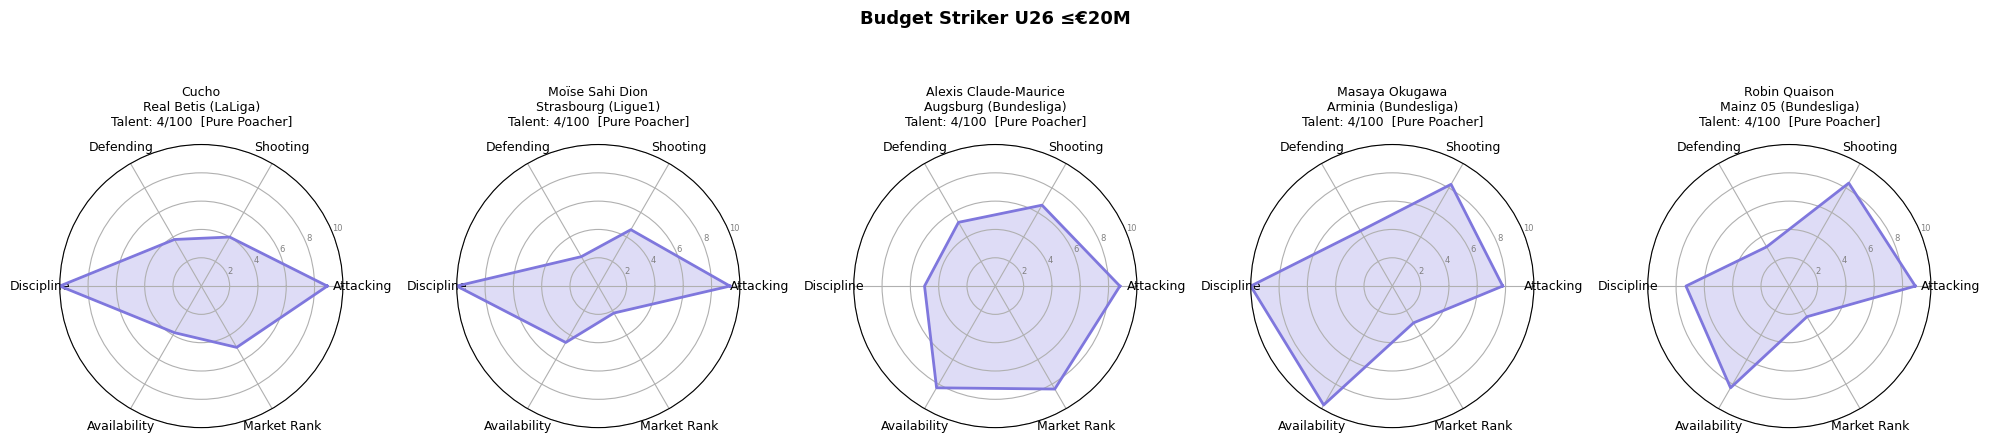

💾 Saved → reports/


In [30]:
# Plot cards for query 1 (budget striker)
if not q1.empty:
    plot_recommendation_cards(q1, title='Budget Striker U26 ≤€20M')

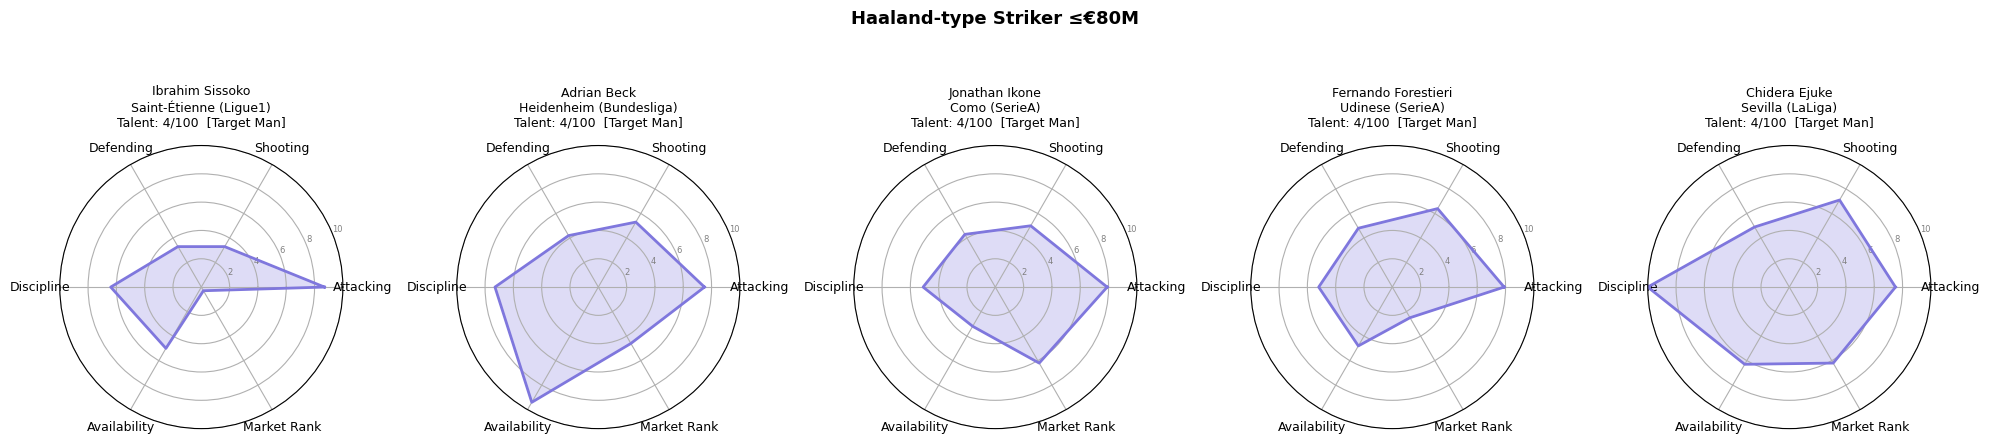

💾 Saved → reports/


In [31]:
# Plot cards for query 2 (Haaland replacement)
if not q2.empty:
    plot_recommendation_cards(q2, title='Haaland-type Striker ≤€80M')

## 🔍 7 — Side-by-Side Player Comparison


────────────────────────────────────────────────────────────
  Erling Haaland  vs  Kylian Mbappé
────────────────────────────────────────────────────────────
                     Erling Haaland     Kylian Mbappé
Age                           24.00             25.00
Squad               Manchester City       Real Madrid
league                          EPL            LaLiga
primary_pos                 Forward           Forward
style_label        Complete Forward  Complete Forward
goals_p90                      0.72              0.96
assists_p90                    0.10              0.09
g_a_p90                        0.82              1.05
shots_p90                      3.59              4.99
shot_accuracy_pct             55.00             52.80
conversion_rate                0.17              0.15
tackles_won_p90                0.20              0.15
interceptions_p90              0.16              0.03
def_actions_p90                0.36              0.19
yellow_p90                     

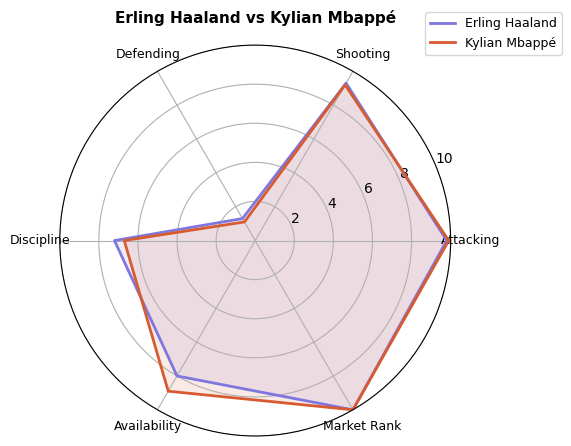

💾 Saved → reports/07_compare_Erling_Haa_vs_Kylian_Mba.png


In [32]:
def compare_players(player_a, player_b):
    """
    Side-by-side stat comparison between two players.
    Returns a formatted DataFrame and plots overlaid radar charts.
    """
    def find(name):
        r = snap[snap['Player'].str.lower() == name.lower()]
        if r.empty:
            r = snap[snap['Player'].str.lower().str.contains(
                name.lower().split()[0], na=False
            )]
        return r.iloc[0] if not r.empty else None

    ra, rb = find(player_a), find(player_b)
    if ra is None or rb is None:
        print(f'  Could not find one or both players.')
        return

    compare_cols = [
        'Age', 'Squad', 'league', 'primary_pos', 'style_label',
        'goals_p90', 'assists_p90', 'g_a_p90', 'shots_p90',
        'shot_accuracy_pct', 'conversion_rate',
        'tackles_won_p90', 'interceptions_p90', 'def_actions_p90',
        'yellow_p90', 'availability_pct',
        'market_value_eur', 'talent_score', 'overall_score',
        'career_goals_p90', 'career_g_a_p90',
    ]
    compare_cols = [c for c in compare_cols if c in snap.columns]

    comp = pd.DataFrame({
        ra['Player']: ra[compare_cols],
        rb['Player']: rb[compare_cols],
    })

    # Format market value rows
    if 'market_value_eur' in comp.index:
        for col in comp.columns:
            v = comp.loc['market_value_eur', col]
            if pd.notna(v) and isinstance(v, (int, float)):
                comp.loc['market_value_eur', col] = f'€{v/1e6:.1f}M'

    print(f'\n{"─"*60}')
    print(f'  {ra["Player"]}  vs  {rb["Player"]}')
    print(f'{"─"*60}')
    print(comp.to_string())

    # Overlaid radar
    fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))

    def pct_score(col, val, invert=False):
        if col not in snap.columns or pd.isna(val): return 5.0
        series = pd.to_numeric(snap[col], errors='coerce').dropna()
        pct = (series < val).mean()
        return round((1 - pct if invert else pct) * 10, 1)

    radar_dims = ['g_a_p90', 'shot_accuracy_pct', 'def_actions_p90',
                  'yellow_p90', 'availability_pct', 'market_value_eur']
    radar_labels = ['Attacking', 'Shooting', 'Defending',
                    'Discipline', 'Availability', 'Market Rank']
    invert_flags = [False, False, False, True, False, False]

    N      = len(radar_dims)
    angles = [n / float(N) * 2 * np.pi for n in range(N)] + [0]

    for r, color, label in [(ra, COLORS[0], ra['Player']), (rb, COLORS[2], rb['Player'])]:
        vals = [pct_score(d, r.get(d, np.nan), inv)
                for d, inv in zip(radar_dims, invert_flags)]
        vals += [vals[0]]
        ax.plot(angles, vals, color=color, linewidth=2, label=label)
        ax.fill(angles, vals, color=color, alpha=0.12)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(radar_labels, size=9)
    ax.set_ylim(0, 10)
    ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=9)
    ax.set_title(f'{ra["Player"]} vs {rb["Player"]}', pad=16, fontsize=11, fontweight='bold')

    plt.tight_layout()
    safe_name = f'{ra["Player"][:10]}_vs_{rb["Player"][:10]}'.replace(' ', '_')
    plt.savefig(REPORTS / f'07_compare_{safe_name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f'💾 Saved → reports/07_compare_{safe_name}.png')
    return comp


# Demo comparison
_ = compare_players('Erling Haaland', 'Kylian Mbappé')

## 💎 8 — Hidden Gems Table

In [33]:
def find_hidden_gems(
    position=None,
    max_value_eur=10_000_000,
    min_talent_score=60,
    max_age=25,
    top_n=20,
):
    """
    Hidden gems: high talent score + low market value.
    These are the players scouts should be watching.
    """
    pool = snap.copy()

    if position:
        pool = apply_hard_filters(pool, position=position)

    if 'talent_score' in pool.columns:
        pool = pool[pd.to_numeric(pool['talent_score'], errors='coerce') >= min_talent_score]

    if 'market_value_eur' in pool.columns:
        mv = pd.to_numeric(pool['market_value_eur'], errors='coerce')
        pool = pool[(mv <= max_value_eur) | mv.isna()]

    age_col = 'Age' if 'Age' in pool.columns else 'age'
    if age_col in pool.columns:
        pool = pool[pd.to_numeric(pool[age_col], errors='coerce') <= max_age]

    pool = pool.sort_values('talent_score', ascending=False, na_position='last')

    display_cols = [
        'Player', 'Age', 'Squad', 'league', 'primary_pos', 'style_label',
        'goals_p90', 'assists_p90', 'def_actions_p90',
        'market_value_eur', 'talent_score'
    ]
    display_cols = [c for c in display_cols if c in pool.columns]
    gems = pool.head(top_n)[display_cols].copy()

    if 'market_value_eur' in gems.columns:
        gems['value_M€'] = (
            pd.to_numeric(gems['market_value_eur'], errors='coerce') / 1e6
        ).round(2)
        gems = gems.drop(columns=['market_value_eur'])

    print(f'💎 Hidden Gems — {position or "All positions"} | max €{max_value_eur/1e6:.0f}M | '
          f'talent≥{min_talent_score} | max {max_age}yo')
    print(f'   Found: {len(gems):,} players')
    print()
    print(gems.to_string(index=False))
    return gems


gems_all = find_hidden_gems(top_n=20)
print()
gems_fw  = find_hidden_gems(position='Forward', top_n=10)

💎 Hidden Gems — All positions | max €10M | talent≥60 | max 25yo
   Found: 0 players

Empty DataFrame
Columns: [Player, Age, Squad, league, primary_pos, style_label, goals_p90, assists_p90, def_actions_p90, talent_score, value_M€]
Index: []

💎 Hidden Gems — Forward | max €10M | talent≥60 | max 25yo
   Found: 0 players

Empty DataFrame
Columns: [Player, Age, Squad, league, primary_pos, style_label, goals_p90, assists_p90, def_actions_p90, talent_score, value_M€]
Index: []


## 📤 9 — Export & Save

In [34]:
import pickle

# ── Package the engine as a callable object ───────────────────────────
engine = {
    'recommend':        recommend,
    'compare_players':  compare_players,
    'find_hidden_gems': find_hidden_gems,
    'snap':             snap,             # unified player table
    'style_labels':     ALL_STYLE_LABELS,
    'knn_model':        knn_model,
    'knn_scaler':       knn_scaler,
    'knn_features':     knn_features,
    'xgb_model':        xgb_model,
    'xgb_features':     xgb_features,
    'cluster_models':   cluster_models,
}

MODELS.mkdir(parents=True, exist_ok=True)
engine_path = MODELS / 'recommendation_engine.pkl'
with open(engine_path, 'wb') as f:
    pickle.dump(engine, f)
print(f'✅ Engine saved → {engine_path}')

# ── Save the unified player snapshot ─────────────────────────────────
snap_path = PROCESSED / 'player_snapshot.csv'
snap.to_csv(snap_path, index=False)
print(f'✅ Player snapshot saved → {snap_path}  ({len(snap):,} rows)')

# ── Save test query results ───────────────────────────────────────────
for name, df in [('q1_budget_striker', q1), ('q2_haaland_type', q2),
                  ('q3_btb_bundesliga', q3), ('q4_young_cb', q4),
                  ('q5_creative_mid', q5)]:
    if not df.empty:
        df.to_csv(PROCESSED / f'rec_{name}.csv', index=False)
        print(f'   Saved rec_{name}.csv')

✅ Engine saved → C:\Users\Lenovo\Scouti_Koora\data\processed\recommendation_engine.pkl
✅ Player snapshot saved → C:\Users\Lenovo\Scouti_Koora\data\processed\player_snapshot.csv  (4,817 rows)
   Saved rec_q1_budget_striker.csv
   Saved rec_q2_haaland_type.csv
   Saved rec_q3_btb_bundesliga.csv
   Saved rec_q4_young_cb.csv
   Saved rec_q5_creative_mid.csv


## 🖨️ 10 — Summary Print for Claude

In [35]:
summary = {
    'engine': {
        'pipeline_steps': [
            '1. Hard filters (position, age, budget, minutes, league)',
            '2. Style filter (K-Means cluster label)',
            '3. Rank by XGBoost talent_score',
            '4. Optional: similarity re-rank vs reference player (KNN cosine)',
        ],
        'api_functions': [
            'recommend(position, style, max_budget_eur, max_age, min_age, reference_player, leagues, top_n)',
            'compare_players(player_a, player_b) → side-by-side table + radar chart',
            'find_hidden_gems(position, max_value_eur, min_talent_score, max_age)',
        ],
        'style_labels': ALL_STYLE_LABELS,
        'player_snapshot_rows': len(snap),
    },
    'test_queries': {
        'q1_budget_striker_u26':    q1['Player'].tolist() if not q1.empty else [],
        'q2_haaland_type':          q2['Player'].tolist() if not q2.empty else [],
        'q3_btb_bundesliga':        q3['Player'].tolist() if not q3.empty else [],
        'q4_young_cb_u23':          q4['Player'].tolist() if not q4.empty else [],
        'q5_creative_mid_salah':    q5['Player'].tolist() if not q5.empty else [],
    },
    'saved_artifacts': [
        'models/recommendation_engine.pkl',
        'data/processed/player_snapshot.csv',
        'data/processed/rec_q1_budget_striker.csv',
        'data/processed/rec_q2_haaland_type.csv',
        'data/processed/rec_q3_btb_bundesliga.csv',
        'data/processed/rec_q4_young_cb.csv',
        'data/processed/rec_q5_creative_mid.csv',
    ],
    'next_notebook': 'notebook 08 — FastAPI Backend',
}

print('=' * 60)
print('  NB07 COMPLETE — RECOMMENDATION ENGINE')
print('=' * 60)
print(json.dumps(summary, indent=2, default=str))

with open(PROCESSED / 'nb07_summary.json', 'w') as f:
    json.dump(summary, f, indent=2, default=str)

print(f"""
{'='*60}
  RECOMMENDATION ENGINE READY:
  Players in snapshot:  {len(snap):,}
  Style labels:         {len(ALL_STYLE_LABELS)}
  API functions:        recommend() | compare_players() | find_hidden_gems()
  → NEXT: notebook 08 — FastAPI Backend
{'='*60}
""")

  NB07 COMPLETE — RECOMMENDATION ENGINE
{
  "engine": {
    "pipeline_steps": [
      "1. Hard filters (position, age, budget, minutes, league)",
      "2. Style filter (K-Means cluster label)",
      "3. Rank by XGBoost talent_score",
      "4. Optional: similarity re-rank vs reference player (KNN cosine)"
    ],
    "api_functions": [
      "recommend(position, style, max_budget_eur, max_age, min_age, reference_player, leagues, top_n)",
      "compare_players(player_a, player_b) \u2192 side-by-side table + radar chart",
      "find_hidden_gems(position, max_value_eur, min_talent_score, max_age)"
    ],
    "style_labels": [
      "Aggressive Stopper",
      "Backup GK",
      "Box-to-Box",
      "Complete Forward",
      "Creative #10",
      "Deep Playmaker",
      "Defensive CB",
      "Defensive Midfielder",
      "Pure Poacher",
      "Shot-stopper",
      "Target Man",
      "Wide Forward"
    ],
    "player_snapshot_rows": 4817
  },
  "test_queries": {
    "q1_budget_striker_u2